In [5]:
# IMPORT
import matplotlib.pyplot as plt
import sys
import os
import math
import seaborn as sns
import pandas as pd
import numpy as np
from collections import Counter
import cv2
import random

current_dir = os.getcwd()
project_root = os.path.dirname(current_dir)
if project_root not in sys.path:
    sys.path.append(project_root)

from src.dataset import UCF101Dataset
from src.dataset2 import UCF101DatasetFast, get_datasets

Initializing Dataset...
Dataset created successfully!
Total videos found: 9537

Loading video at index 1...
------------------------------
Label Index: 0
Tensor Shape: torch.Size([3, 16, 224, 224])
------------------------------
TEST PASSED: Tensor format is correct (C, T, H, W).
Visualizing 16 extracted frames...


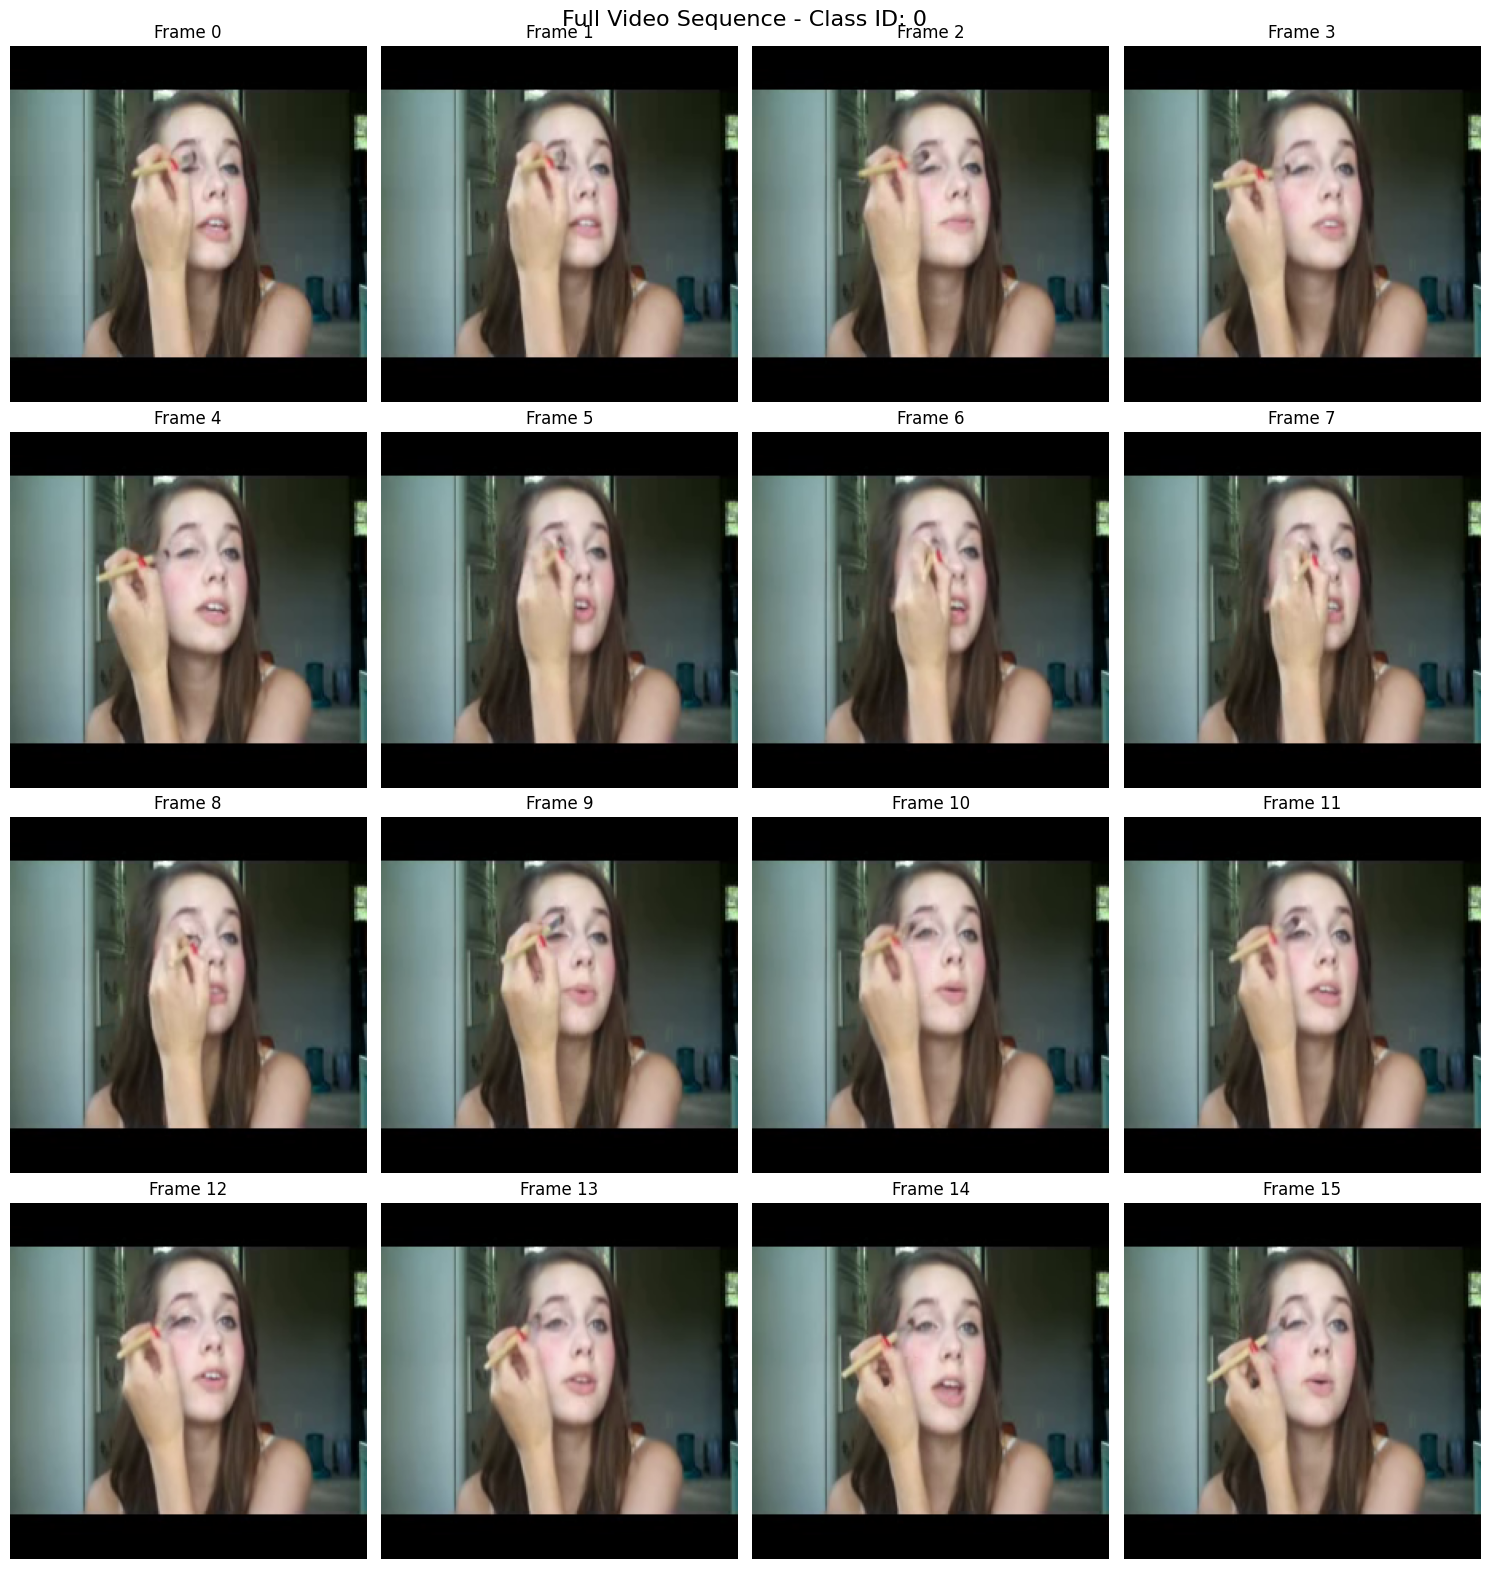

In [6]:
def show_video_grid(video_tensor, label_idx, cols=4):
    """
    Displays frames of a video tensor in a grid.
    Args:
        video_tensor: Tensor shape (C, T, H, W)
        label_idx: The class index (int)
        cols: Number of columns in the grid
    """
    # Reorder dimensions for Matplotlib: (C, T, H, W) -> (T, H, W, C)
    frames = video_tensor.permute(1, 2, 3, 0)
    
    # move to CPU and convert to numpy
    if frames.is_cuda:
        frames = frames.cpu()
    frames = frames.numpy()

    num_frames = frames.shape[0]  # Should be 16
    rows = math.ceil(num_frames / cols) 

    fig, axes = plt.subplots(rows, cols, figsize=(15, 4 * rows))
    fig.suptitle(f"Full Video Sequence - Class ID: {label_idx}", fontsize=16)

    axes = axes.flatten()

    for i in range(len(axes)):
        if i < num_frames:
            # Note: values are already 0-1 due to division by 255 in Dataset
            axes[i].imshow(frames[i])
            axes[i].set_title(f"Frame {i}")
            axes[i].axis('off') 
        else:
            axes[i].axis('off')

    plt.tight_layout()
    plt.show()


root_video = "UCF-101"                     
path_trainlist = "ucfTrainTestlist/trainlist01.txt" 
path_classind = "ucfTrainTestlist/classInd.txt"     

print("Initializing Dataset...")

try:
    dataset = UCF101Dataset(
        data_root=root_video,
        annotation_file=path_trainlist,
        class_ind_file=path_classind,
        frames_per_clip=16  
    )

    print(f"Dataset created successfully!")
    print(f"Total videos found: {len(dataset)}")


    print("\nLoading video at index 1...")
    video_tensor, label_idx = dataset[1]

    print("-" * 30)
    print(f"Label Index: {label_idx}")
    print(f"Tensor Shape: {video_tensor.shape}")
    print("-" * 30)

    if video_tensor.shape[0] == 3 and video_tensor.shape[1] == 16:
        print("TEST PASSED: Tensor format is correct (C, T, H, W).")
    else:
        print("WARNING: Unexpected format (check permute or transform logic).")

    print(f"Visualizing {video_tensor.shape[1]} extracted frames...")
    show_video_grid(video_tensor, label_idx)

except FileNotFoundError as e:
    print(f"\nERROR: Files not found! Check your paths.\n{e}")
except Exception as e:
    print(f"\nGENERAL ERROR:\n{e}")




Loading Datasets...
--------------------------------------------------
GROUP-BASED SPLIT SUMMARY:
Train samples: 7675, ['JumpingJack_g17', 'RopeClimbing_g22', 'HighJump_g18', 'MoppingFloor_g12', 'PlayingFlute_g08', 'Nunchucks_g17', 'MilitaryParade_g23', 'UnevenBars_g23', 'HighJump_g22', 'WritingOnBoard_g23', 'Archery_g11', 'TennisSwing_g14', 'HeadMassage_g18', 'ApplyLipstick_g09', 'Kayaking_g17', 'BabyCrawling_g10', 'Swing_g10', 'CricketShot_g09', 'ApplyEyeMakeup_g21', 'RockClimbingIndoor_g20', 'FrisbeeCatch_g11', 'HorseRace_g09', 'RockClimbingIndoor_g21', 'PoleVault_g25', 'HorseRiding_g15', 'VolleyballSpiking_g20', 'FrisbeeCatch_g17', 'HorseRiding_g12', 'TaiChi_g08', 'WalkingWithDog_g12', 'BlowDryHair_g25', 'CricketBowling_g25', 'PoleVault_g15', 'IceDancing_g23', 'TaiChi_g17', 'CleanAndJerk_g25', 'VolleyballSpiking_g14', 'BreastStroke_g21', 'YoYo_g13', 'BreastStroke_g15', 'YoYo_g22', 'Diving_g17', 'BoxingSpeedBag_g19', 'FrisbeeCatch_g08', 'PlayingDhol_g22', 'PlayingGuitar_g20', 'Socce

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.5179958].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.0151556..2.4308496].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.0151556..1.9602616].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.4482791].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.0494049..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.1007793..2.3785625]

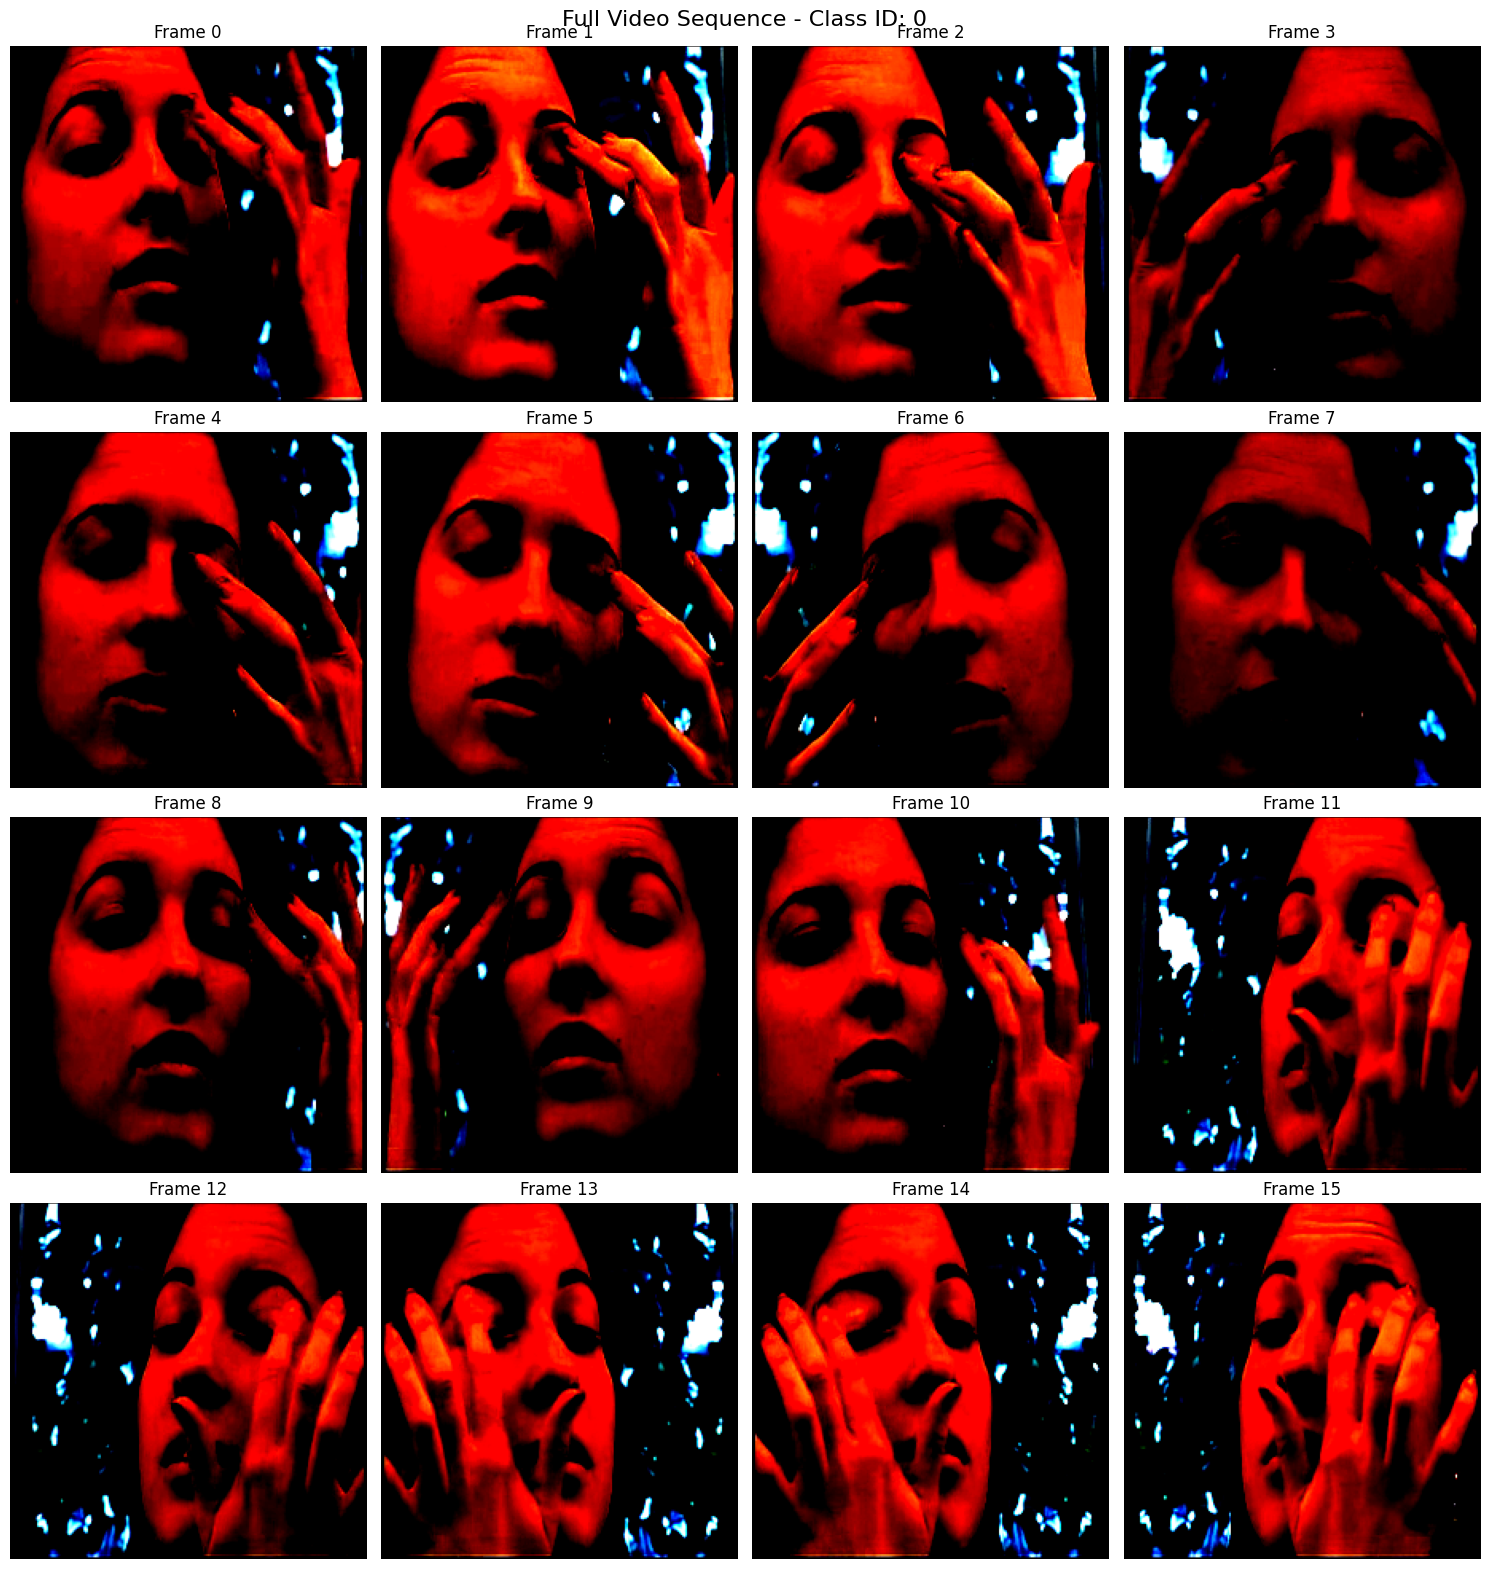

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].
Clipping input data to the 

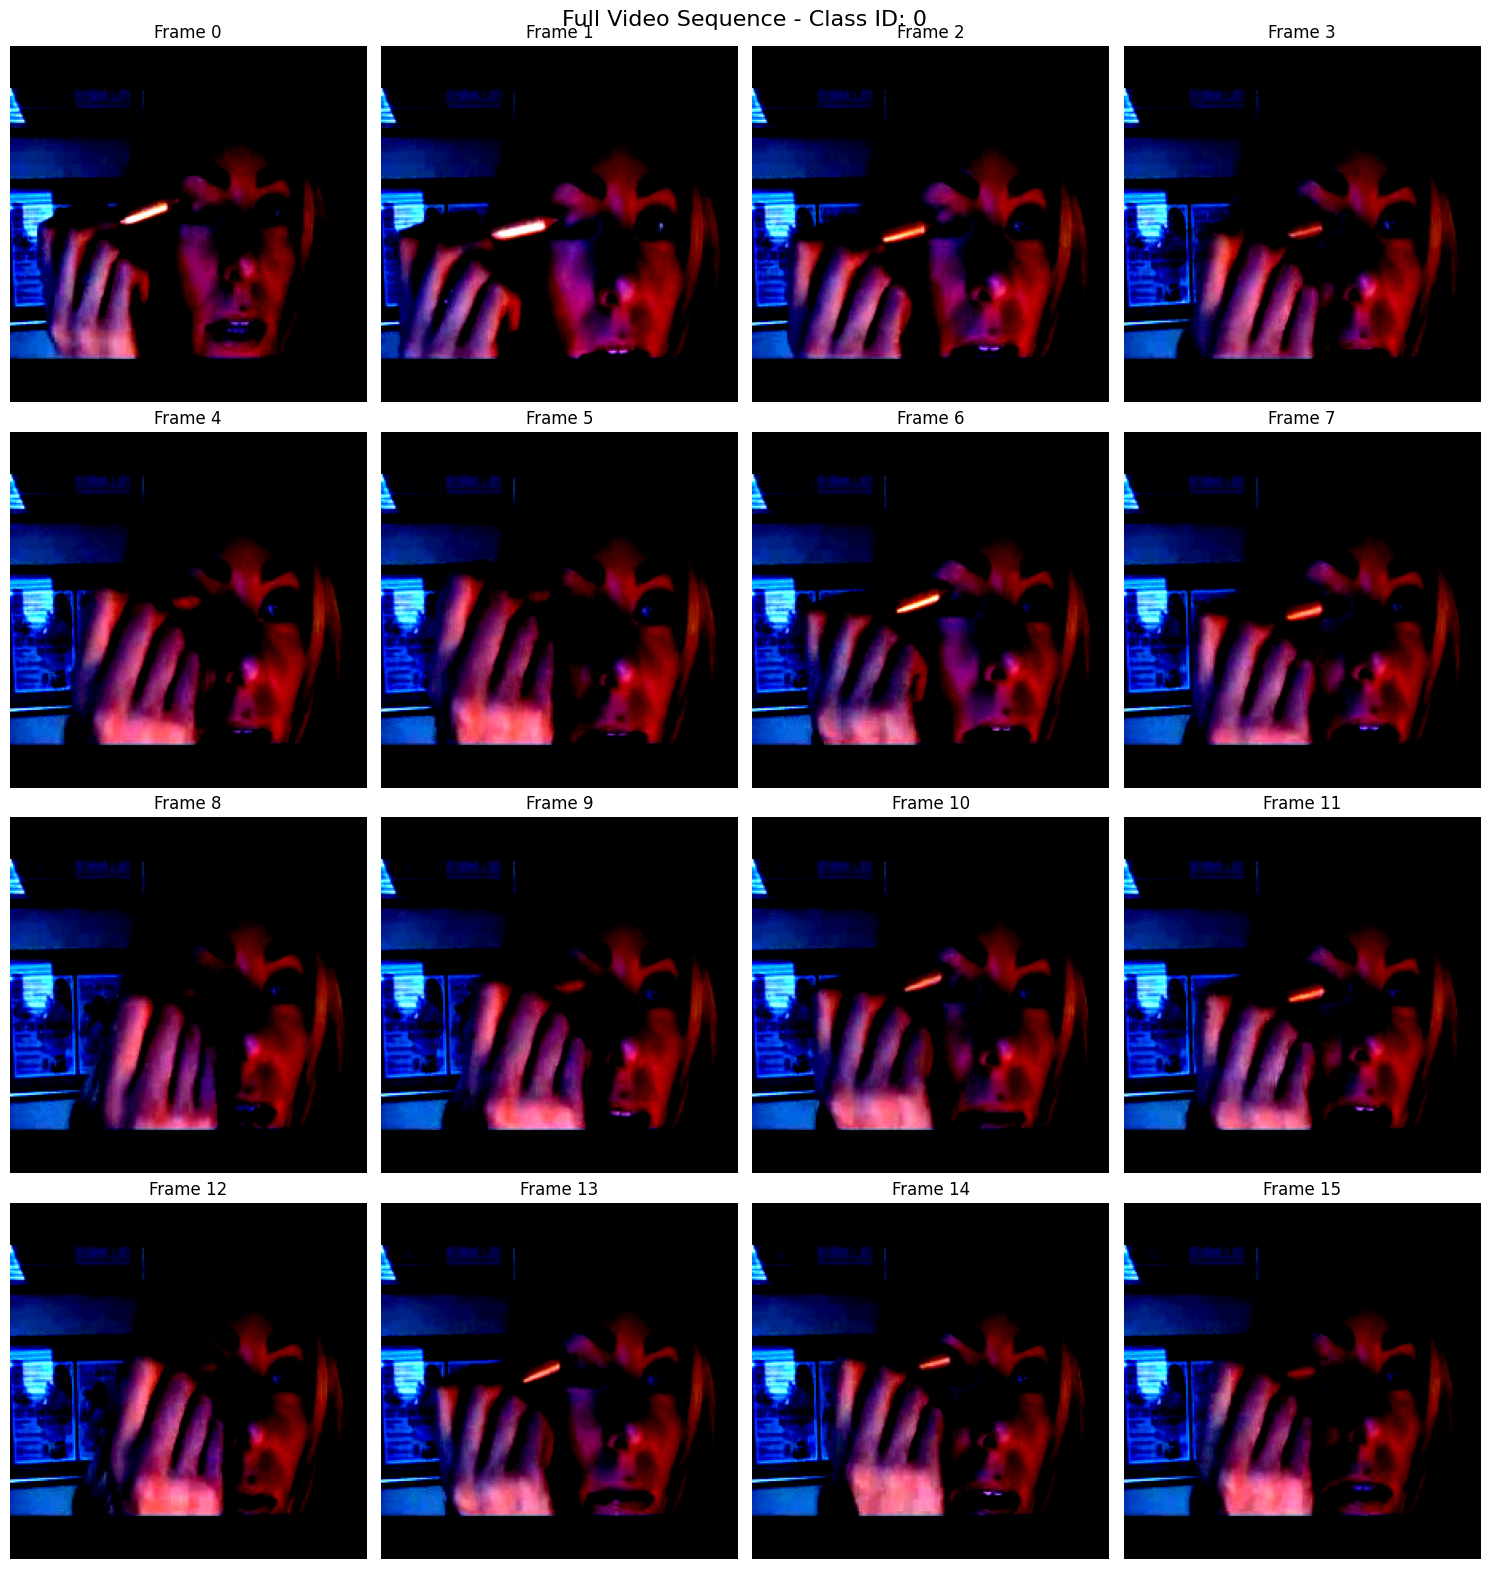

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.622571].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.5702832].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.6051416].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.6051416].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.5702832].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.5877128].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64]

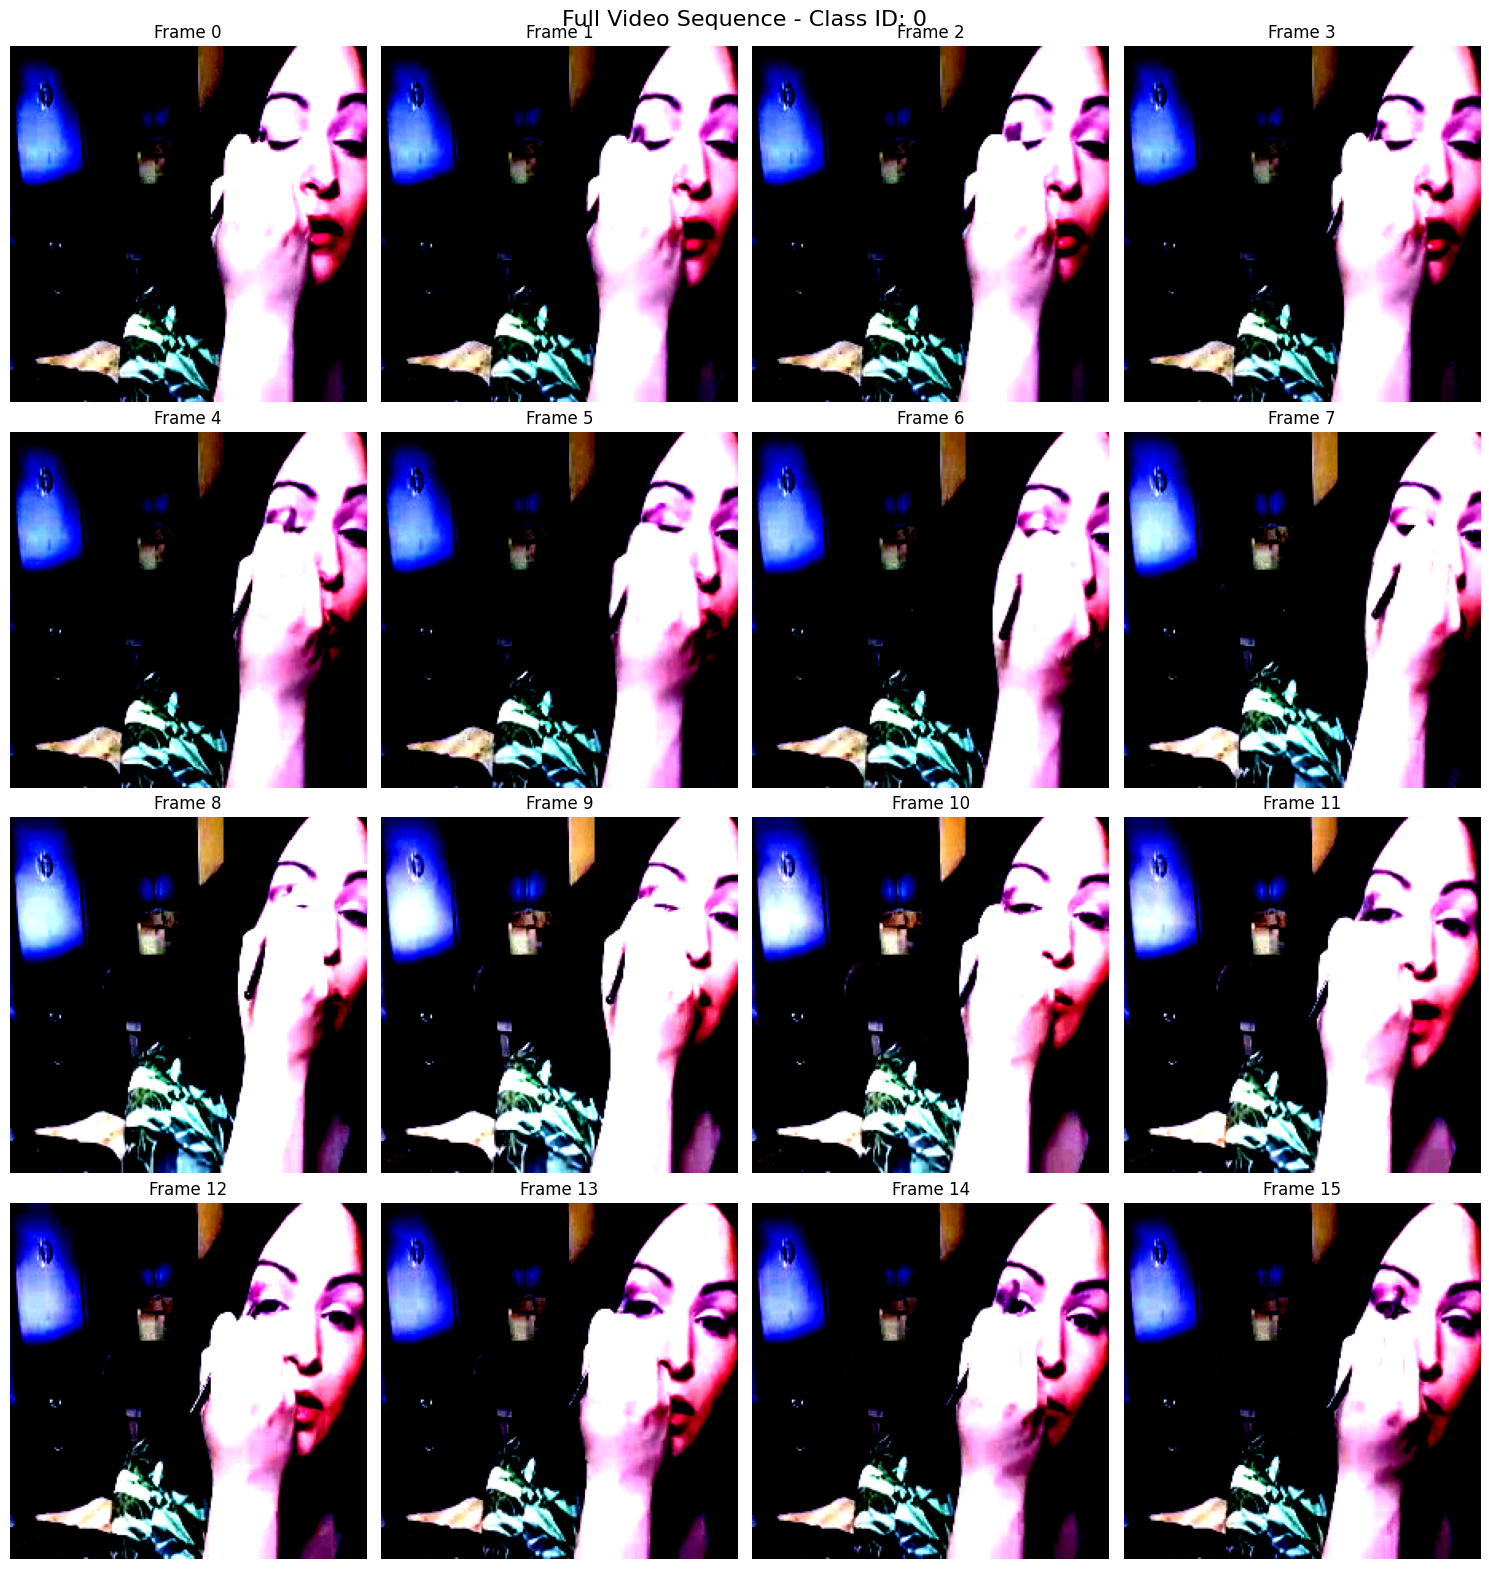

✅ Classi uniche nel Training:   101 / 101
✅ Classi uniche nella Validation: 101 / 101
✅ Classi uniche nel Test:       1 / 101


In [7]:
def find_index_by_label(dataset, target_label=0):
    """
    Cerca il primo indice disponibile nel dataset che corrisponde alla label target.
    """
    for i, (path, label) in enumerate(dataset.samples):
        if label == target_label:
            return i
    return None

try:
    config = {
        "DATA_ROOT" : "temp_jpg_224",
        "TRAIN_ANNOTATION_FILE": "ucfTrainTestlist/trainlist01.txt",
        "TEST_ANNOTATION_FILE" : "ucfTrainTestlist/testlist01.txt",
        "CLASS_IND_FILE": "ucfTrainTestlist/classInd.txt",
        "FRAMES_PER_CLIP": 16,
        "RESIZE_HEIGHT" : 224,
        "RESIZE_WIDTH" : 224
    }
    
    print("Loading Datasets...")
    train_ds, val_ds, test_ds = get_datasets(config)

    target_id = 0 
    
    idx_train = find_index_by_label(train_ds, target_id)
    idx_val   = find_index_by_label(val_ds, target_id)
    idx_test  = find_index_by_label(test_ds, target_id)

    if None in [idx_train, idx_val, idx_test]:
        print(f"⚠️ Warning: Class ID {target_id} not found in one of the datasets.")
    else:
        print(f"\nLoading video for Class ID {target_id} from all sets...")
        
        video_train, label_train = train_ds[idx_train]
        video_val, label_val     = val_ds[idx_val]
        video_test, label_test   = test_ds[idx_test]

        print("-" * 30)
        print(f"TRAIN - Label: {label_train} | Index found: {idx_train} | Shape: {video_train.shape}")
        print(f"VAL   - Label: {label_val} | Index found: {idx_val} | Shape: {video_val.shape}")
        print(f"TEST  - Label: {label_test} | Index found: {idx_test} | Shape: {video_test.shape}")
        print("-" * 30)

        print(f"Visualizing frames for Class {target_id}...")
        show_video_grid(video_train, label_train)
        show_video_grid(video_val, label_val)
        show_video_grid(video_test, label_test)
        
        train_labels = set([s[1] for s in train_ds.samples])
        val_labels   = set([s[1] for s in val_ds.samples])
        test_labels  = set([s[1] for s in test_ds.samples])

        print(f"✅ Classi uniche nel Training:   {len(train_labels)} / 101")
        print(f"✅ Classi uniche nella Validation: {len(val_labels)} / 101")
        print(f"✅ Classi uniche nel Test:       {len(test_labels)} / 101")

        # Se vuoi vedere se manca qualcosa di specifico
        if len(val_labels) < 101:
            missing = set(range(101)) - val_labels
            print(f"❌ Classi mancanti nella Val: {missing}")

except FileNotFoundError as e:
    print(f"\nERROR: Files not found! Check your paths.\n{e}")
except Exception as e:
    print(f"\nGENERAL ERROR:\n{e}")



# Exploratory Data Analysis of the UCF101 Dataset

CLASS DISTRIBUTION ANALYSIS
Total Classes: 101
Max samples in a class: 121
Min samples in a class: 72
Average samples per class: 94.43


C:\Users\rikyf\AppData\Local\Temp\ipykernel_3300\2039887610.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=df_classes.index, y=df_classes['Count'], palette='viridis')


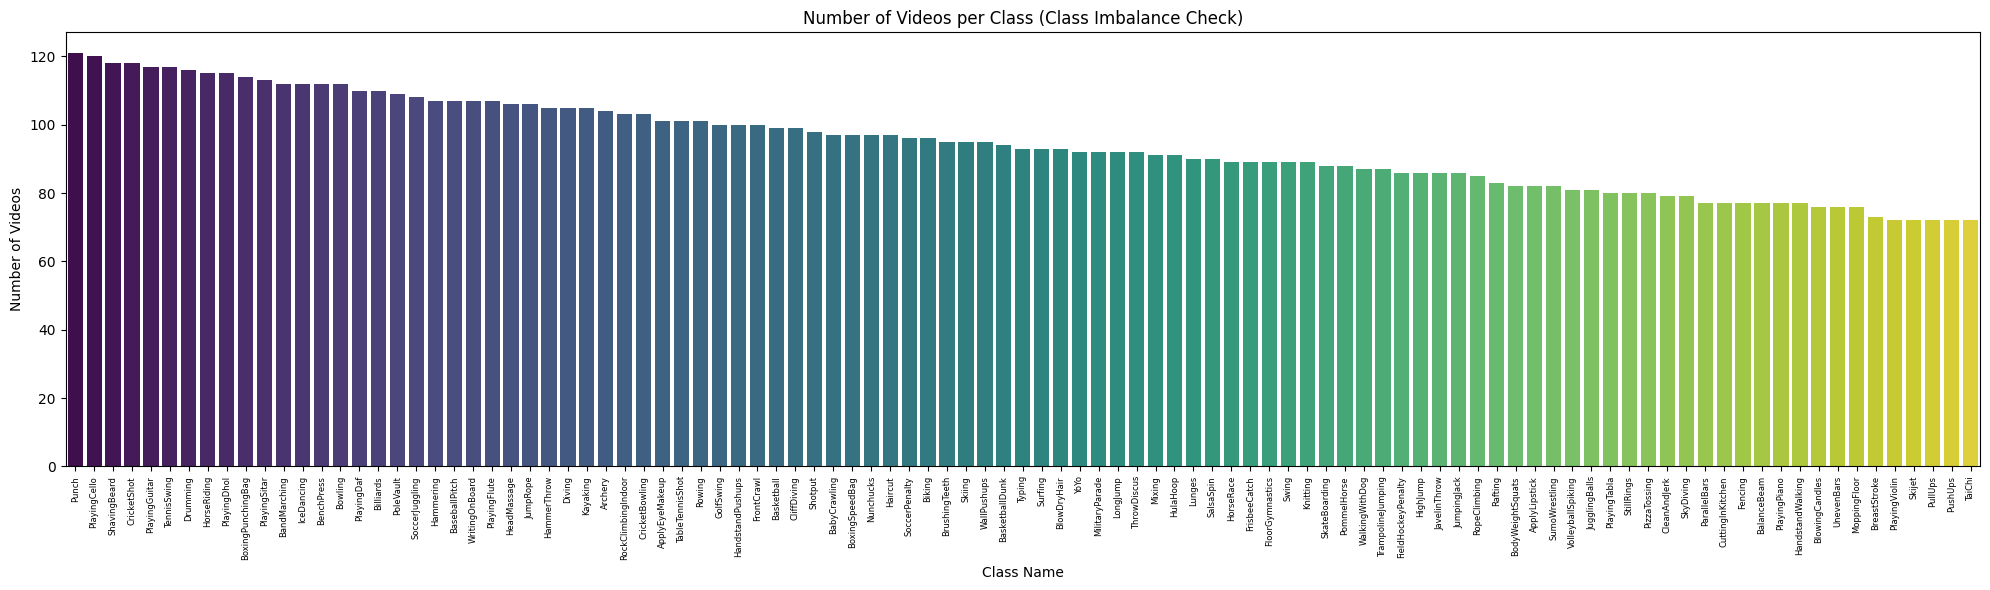


VIDEO PROPERTIES ANALYSIS (Subset)
Analyzing a random subset of 200 videos to estimate lengths and resolutions...


100%|██████████| 200/200 [00:05<00:00, 39.51it/s]


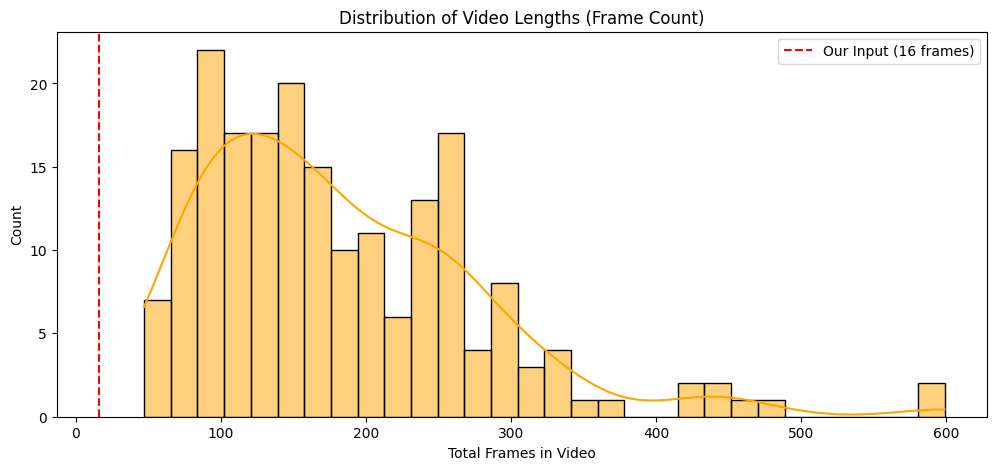

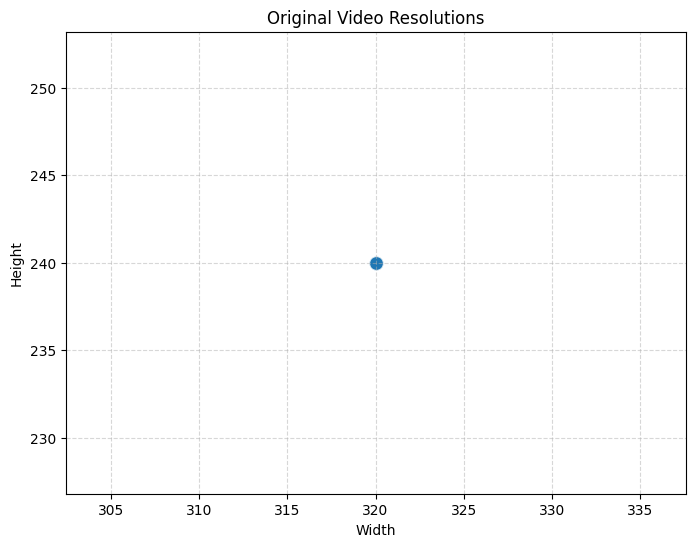

In [4]:
def analyze_dataset(dataset, sample_size=200):

    print("CLASS DISTRIBUTION ANALYSIS")
    
    # Get all labels from the dataset
    all_labels = dataset.labels
    
    # get names back
    idx_to_class = {v: k for k, v in dataset.class_to_idx.items()}
    all_class_names = [idx_to_class[idx] for idx in all_labels]
    
    # Count occurrences
    class_counts = Counter(all_class_names)
    df_classes = pd.DataFrame.from_dict(class_counts, orient='index', columns=['Count']).sort_values('Count', ascending=False)
    
    print(f"Total Classes: {len(df_classes)}")
    print(f"Max samples in a class: {df_classes['Count'].max()}")
    print(f"Min samples in a class: {df_classes['Count'].min()}")
    print(f"Average samples per class: {df_classes['Count'].mean():.2f}")
    
    plt.figure(figsize=(20, 6))
    sns.barplot(x=df_classes.index, y=df_classes['Count'], palette='viridis')
    plt.xticks(rotation=90, fontsize=6)
    plt.title("Number of Videos per Class (Class Imbalance Check)")
    plt.xlabel("Class Name")
    plt.ylabel("Number of Videos")
    plt.tight_layout()
    plt.show()
    
    print("\nVIDEO PROPERTIES ANALYSIS (Subset)")
    print(f"Analyzing a random subset of {sample_size} videos to estimate lengths and resolutions...")
    
    # sample randomly to avoid opening 13k videos
    random_indices = random.sample(range(len(dataset)), min(sample_size, len(dataset)))
    
    video_stats = []
    
    for idx in tqdm(random_indices):
        video_path = dataset.video_paths[idx]
        
        cap = cv2.VideoCapture(video_path)
        if not cap.isOpened():
            continue
            
        frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
        height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
        fps = cap.get(cv2.CAP_PROP_FPS)
        
        # Calculate duration in seconds
        duration = frame_count / fps if fps > 0 else 0
        
        video_stats.append({
            'Frame Count': frame_count,
            'Width': width,
            'Height': height,
            'FPS': fps,
            'Duration (sec)': duration
        })
        cap.release()
        
    df_stats = pd.DataFrame(video_stats)
    
    # Frame Count Distribution
    plt.figure(figsize=(12, 5))
    sns.histplot(df_stats['Frame Count'], kde=True, bins=30, color='orange')
    plt.axvline(x=16, color='r', linestyle='--', label='Our Input (16 frames)')
    plt.title("Distribution of Video Lengths (Frame Count)")
    plt.xlabel("Total Frames in Video")
    plt.legend()
    plt.show()
    
    # Resolution Scatter
    plt.figure(figsize=(8, 6))
    sns.scatterplot(data=df_stats, x='Width', y='Height', alpha=0.6, s=100)
    plt.title("Original Video Resolutions")
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()

    
    return df_classes, df_stats

df_classes, df_stats = analyze_dataset(dataset)

### 1. Class Distribution Analysis

The bar chart titled **"Number of Videos per Class"** illustrates the frequency of samples across the 101 action categories.

* **Statistical Observations:**
    * The dataset exhibits a **moderate class imbalance**.
    * **Maximum Frequency:** The most represented class (*Punch*) contains **121** samples.
    * **Minimum Frequency:** The least represented class (*TaiChi*) contains **72** samples.
    * **Mean:** The average number of samples per class is approximately **94.4**.

* **Implications for Training:**
    The ratio between the majority and minority classes is less than 2:1. While the distribution is not perfectly uniform, the imbalance is not severe enough to necessitate aggressive synthetic oversampling techniques (e.g., SMOTE) or weighted loss functions.
    * **Mitigation Strategy:** I will employ **Random Shuffling** within the `DataLoader`. This ensures that each training batch contains a stochastic mix of classes, preventing the model from developing a bias toward the more frequent actions during the gradient descent optimization.

---

### 2. Temporal Analysis (Video Duration)

The histogram **"Distribution of Video Lengths"** visualizes the frame count density across the dataset.


* **Justification for Temporal Subsampling:**
    Reducing a video from ~200 frames to a tensor of temporal depth $T=16$ represents a significant compression factor. However, this design choice is theoretically grounded in two principles:
    1.  **High Temporal Redundancy:** In video data, adjacent frames are highly correlated and contain minimal distinct semantic information (inter-frame redundancy). Processing every frame would result in computational inefficiency without a proportional gain in feature extraction capability.
    2.  **Global Uniform Sampling Strategy:** Crucially, my pipeline does not merely truncate the video to the *first* 16 frames. By utilizing a uniform sampling function (`np.linspace`), I extract frames at equidistant intervals across the **entire duration** of the video clip.
        * *Effect:* This preserves the global temporal structure of the action (onset, nucleus, and offset) while maintaining a manageable tensor size ($Batch \times 3 \times 16 \times 224 \times 224$) **compatible with GPU memory constraints**.

---

### 3. Spatial Analysis (Resolution and Aspect Ratio)

The scatter plot **"Original Video Resolutions"** displays the width (x-axis) versus height (y-axis) of the raw video files.

* **Statistical Observations:**
    The plot reveals a single, dense cluster at the coordinates **(320, 240)**.
* **Significance of the Result:**
    This observation confirms that the dataset possesses **perfect spatial consistency**. Unlike uncurated web datasets which often contain mixed aspect ratios (vertical, horizontal, square), UCF101 is standardized.
    * **Preprocessing Implication:** The native aspect ratio is 4:3. Consequently, the mandatory resizing operation to the **$224 \times 224$** resolution (required by standard CNN backbones like ResNet) will apply a uniform geometric transformation across all samples. This consistency eliminates the need for complex pre-processing heuristics such as center-cropping or padding, ensuring that the spatial features remain comparable across the entire dataset.

---

### 4. Conclusion and Pipeline Configuration

Based on the statistical evidence presented above, I have configured the data loading pipeline as follows:

1.  **Spatial Transformation:** Bilinear interpolation to resize frames from $320 \times 240$ to **$224 \times 224$** (standard ImageNet input size).
2.  **Temporal Transformation:** Uniform sparse sampling of **16 frames** to capture long-range temporal dependencies while removing redundancy and **constained by GPU memory**.
3.  **Normalization:** Pixel values are normalized to the $[0, 1]$ range.

---